# Deep learning object detection to estimate the nectar sugar mass of flowering vegetation — reproduction

**Paper**: Hicks, D.M., Baude, M., Kratz, C., Ouvrard, P. & Stone, G.N. (2021).
*Deep learning object detection to estimate the nectar sugar mass of flowering vegetation.*
**Ecological Solutions and Evidence** 2(3): e12099. DOI: [10.1002/2688-8319.12099](https://doi.org/10.1002/2688-8319.12099) (CC BY 4.0).

**Author code** (MIT): Zenodo [10.5281/zenodo.5347794](https://doi.org/10.5281/zenodo.5347794) — `CNN_train_VM_and_predict.py`, `CNN_nectar_sugar_-_plots.R`.
**Author dataset** (CC0): Dryad [10.5061/dryad.63xsj3v34](https://doi.org/10.5061/dryad.63xsj3v34) (version 7), mirrored by the authors on Zenodo record [5347857](https://zenodo.org/records/5347857).

## Scope of this notebook (minimal reproduction)

1. **Inference with the released final model** (`model_weights_all_VMval14.pth`, Faster R-CNN, 26 classes) on a
   deterministic 50-image sample of the released 402-image internal validation set (`validation.7z`),
   following the author's exact pipeline: `detecto` predict + non-max suppression with IoU 0.1
   (the paper states *no lower confidence level was enforced*, Section 2.5).
2. **Detection metrics** (precision / recall / F1) against the released Pascal-VOC labels of those images,
   as a function of the confidence threshold — the paper's own suggested optimisation (Section 4.1).
   **Expected result**: the released model + released internal validation set do **not** reach the paper's
   external 50-image test values (precision 0.90, recall 0.86, F1 0.88, Section 3.2); the measured values and
   the discrepancy are reported honestly below.
3. **Counts → nectar sugar mass per image** using the paper's Table 1 per-taxon model-tag values (µg/day).
4. **Released-CSV analyses** — faithful Python ports (AI-adapted) of the author's R script:
   validation-loss curves and the 30-randomisation quadrat replicate curves (paper Figure 4).

**Execution status**: executed end-to-end on a Google Colab **CPU** runtime (see validation record at the end).

> **AI-assisted adaptation note / AI補助による翻訳について**: The authors did not provide this Colab notebook.
> The model-loading/inference code reuses the authors' `detecto` library and the class list from
> `CNN_train_VM_and_predict.py` verbatim; the R plots are ported to Python with identical logic; the metric
> definitions follow paper Section 3.2 with an explicitly stated IoU ≥ 0.5 + taxon-match assumption (the paper
> does not state its matching IoU). The executed example and listed checks were validated, but untested
> behaviour is not guaranteed. / 本ノートブックは著者提供版ではなくAI補助で作成した reproduction です。
> 推論部は著者の `detecto` コードをそのまま利用し、R の図は同一ロジックで Python に移植しています。

## Runtime selection / 実行環境の選択

**Select `Runtime → Change runtime type → CPU` (recommended).** The paper reports 5.5 s per image on a
2012 laptop CPU; this demo runs ~50 images in several minutes on a standard Colab CPU runtime. No GPU is
required; the code also runs on a T4 GPU without changes (detecto selects CUDA automatically when present).
Run all: `Runtime → Run all`. Expected total ≈ 15–25 min, dominated by a ≈1.24 GB download.

**Downloads / ダウンロード**: ≈1.24 GB from Zenodo (weights 166 MB + validation images archive 1.07 GB).

**Why the Zenodo mirror? / なぜ Zenodo ミラーか**: The Dryad version-7 file listing pins sha-256 values for
every file, but in October 2026 Dryad's download endpoints require an API bearer token
(`HTTP 401, "Unauthorized, must have current bearer token"`) and its browser route serves an anti-bot
challenge to automated clients. The authors' own Zenodo record 5347857 (metadata DOI =
10.5061/dryad.63xsj3v34, same 5 creators, resource type Dataset) hosts byte-identical files; this notebook
verifies the downloaded bytes against the pinned Dryad sha-256 values below.

In [ ]:
import torch, torchvision, sys, platform
print("python:", sys.version.split()[0], "| torch:", torch.__version__, "| torchvision:", torchvision.__version__)
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print("device used by detecto:", device)

python: 3.13.16 | torch: 2.11.0+cpu | torchvision: 0.26.0+cpu
device used by detecto: cpu


**Install the author's library.** `detecto` (PyPI 1.0.x–1.2.x) wraps torchvision's Faster R-CNN and is
the exact library of the authors' script. We install it without dependencies to avoid touching the
preinstalled OpenCV/NumPy stack; `pandas`, `matplotlib`, `tqdm` are already present on Colab.
/ 著者のスクリプトが使用した `detecto` を依存関係なしでインストールします（Colab に事前導入済みの OpenCV 等を保護）。

In [ ]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "py7zr"],
                   capture_output=True, text=True)
print(r.stdout[-300:]); print(r.stderr[-300:])
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "detecto==1.2.2"],
                   capture_output=True, text=True)
print(r.stdout[-500:]); print(r.stderr[-500:])
import detecto
print("detecto:", detecto.__file__)



detecto: /usr/local/lib/python3.13/dist-packages/detecto/__init__.py


**Configuration and constants.** Class list copied verbatim from `CNN_train_VM_and_predict.py`
(lines 45–48/98–102, 25 taxa + `'other spp.'`); per-taxon model-tag nectar sugar masses transcribed from
paper Table 1 (µg/day per tag); file checksums pinned from the Dryad version-7 API file listing.
/ クラスリストは著者スクリプトから、糖量は論文 Table 1 から、チェックサムは Dryad v7 API から不変値として設定します。

In [ ]:
import hashlib, io, json, os, time, urllib.request
import numpy as np
import pandas as pd

CLASSES = ['other spp.', 'Achillea millefolium', 'Angelica sylvestris', 'Bellis perennis',
 'Centaurea nigra', 'Cirsium arvense', 'Cirsium vulgare', 'Heracleum sphondylium',
 'Knautia arvensis', 'Lathyrus pratensis', 'Leucanthemum vulgare', 'Lotus spp.',
 'Prunella vulgaris', 'Raununculus spp.', 'Rubus fruticosus agg.', 'Senecio jacobaea',
 'Silene dioica/latifolia', 'Stachys sylvatica', 'Symphytum officinale', 'Taraxacum agg.',
 'Trifolium pratense', 'Trifolium repens', 'Vicia cracca', 'Vicia sepium/sativa',
 'yellow composite', 'Rhinanthus minor']

# Paper Table 1: nectar sugar mass value of each model tag (µg/day). 'Vicia sepium/sativa' maps to
# the Table 1 'Vicia sepium' row; 'other spp.' has no nectar value and is excluded from mass totals.
SUGAR_UG_PER_TAG = {
 'Achillea millefolium': 220.32, 'Angelica sylvestris': 187.92, 'Bellis perennis': 65.43,
 'Centaurea nigra': 6089.74, 'Cirsium arvense': 4574.31, 'Cirsium vulgare': 8628.74,
 'Heracleum sphondylium': 1472.55, 'Knautia arvensis': 9861.29, 'Lathyrus pratensis': 1905.38,
 'Leucanthemum vulgare': 2652.73, 'Lotus spp.': 215.52, 'Prunella vulgaris': 578.32,
 'Raununculus spp.': 141.18, 'Rhinanthus minor': 435.60, 'Rubus fruticosus agg.': 1892.83,
 'Senecio jacobaea': 2604.66, 'Silene dioica/latifolia': 595.64, 'Stachys sylvatica': 622.22,
 'Symphytum officinale': 4923.65, 'Taraxacum agg.': 3397.82, 'Trifolium pratense': 1982.71,
 'Trifolium repens': 488.84, 'Vicia cracca': 891.93, 'Vicia sepium/sativa': 351.21,
 'yellow composite': 1001.11,
}

# Pinned sha-256 values (Dryad version 137463 file listing, retrieved 2026-10-26)
SHA256 = {
 'model_weights_all_VMval14.pth': '7c3a7c0b77ee89eec3dcfa41084176e0d29dbe9e6e672c2a9b6b38cd47acf191',
 'validation.7z': '9fb66c9eab7a4ad617bac3547755b03135d724caedaeffe6df0fe1b95379cca9',
 'validationdata3.csv': '935d661dbaf33c3702b3448ed6afc4855fc8f682cb207dd655338c66925d0369',
 'quadratsCNN2.csv': 'cd1a20bb2acd160127edd729c94a858e97374eeb72a9c381e9f2bf327b3c6e6a',
 'quadratsHUMANS2.csv': 'eb6ebd4657467de3fd403ef69a274e0b482cddd63b410e570f8321ca8cbb6d71',
 'README.txt': '61f8c9f2573e421e8fff25d4a37c30d94edceb02e8d5d841b861f284bdbf93b3',
}

N_IMAGES = 50      # deterministic sample size, mirroring the paper's 50-image test protocol
SEED = 42          # numpy RandomState seed for the sample and for the replicate randomisations

ZENODO_RECORD = 'https://zenodo.org/api/records/5347857'
print("Configuration ready.")

Configuration ready.


**Download the released CSV tables and README from the authors' Zenodo record 5347857.** Each file's
sha-256 is verified against the value pinned in the Dryad version-7 file listing, so a corrupted or
substituted payload cannot silently pass. / Zenodo レコード 5347857 から CSV と README を取得し、Dryad v7 で固定された sha-256 と照合します。

In [ ]:
def zenodo_files(record_url):
    req = urllib.request.Request(record_url, headers={'User-Agent': 'colab-repro/1.0'})
    d = json.loads(urllib.request.urlopen(req, timeout=180).read())
    return {f['key']: f['links']['self'] for f in d['files']}

FILES = zenodo_files(ZENODO_RECORD)

def fetch_verified(key):
    t0 = time.time()
    b = urllib.request.urlopen(FILES[key], timeout=1800).read()
    h = hashlib.sha256(b).hexdigest()
    assert h == SHA256[key], f"{key}: sha-256 mismatch\n got {h}\n want {SHA256[key]}"
    print(f"{key}: {len(b):,} B in {time.time()-t0:.1f}s — sha-256 OK")
    return b

os.makedirs('/content/nectar_repro', exist_ok=True)
for key in ['validationdata3.csv', 'quadratsCNN2.csv', 'quadratsHUMANS2.csv', 'README.txt']:
    open(f'/content/nectar_repro/{key}', 'wb').write(fetch_verified(key))

validationdata3.csv: 6,136 B in 0.4s — sha-256 OK


quadratsCNN2.csv: 510 B in 0.4s — sha-256 OK


quadratsHUMANS2.csv: 629 B in 0.4s — sha-256 OK


README.txt: 969 B in 0.4s — sha-256 OK


**Dataset provenance check.** We print the dataset README shipped by the authors — it defines each file's
role in the published workflow. / 著者同梱の README を表示し、各ファイルの役割を確認します。

In [ ]:
print(open('/content/nectar_repro/README.txt').read())

Deep learning object detection to estimate the nectar sugar mass of flowering vegetation
Hicks, D.M., Baude, M., Kratz, C., Ouvrard, P. & Stone, G.N.
Ecological Solutions and Evidence, 2021


The model is trained on the .jpg images and .kml files in folder 'traintogoin.7z', and validated on the .jpg images and .kml files in folder 'validation.7z'.

The Python script 'CNN_nectar_sugar_-_train_in_VM_and_predict.py' is used to train the model, adjust the image transforms and training specifications, and save the final model weights.

The same Python script is used to run the model on new images, perform non-max suppression, and output visual and spreadsheet files of the model's predictions.

The R script 'CNN_nectar_sugar_-_plots.R' and associated .csv files are used to plot the validation exercises and produce the figures of the published paper.

The model weights file 'model_weights_all_VMval14.pth' is the final model of the published paper.



**Download the final model weights (166 MB).** `model_weights_all_VMval14.pth` is the paper's final model
per the README. sha-256 verified, then inspected: detecto's `Model.save` stores the plain torchvision
Faster R-CNN `state_dict`, whose box-predictor must output 27 classes (25 taxa + `'other spp.'` + background).
/ 最終モデル重み (166 MB) を検証付きで取得し、27 クラス分類ヘッドの形状を確認します。

In [ ]:
import torch
wb = fetch_verified('model_weights_all_VMval14.pth')
open('/content/nectar_repro/model_weights_all_VMval14.pth', 'wb').write(wb)
sd = torch.load('/content/nectar_repro/model_weights_all_VMval14.pth', map_location='cpu')
print('state_dict keys:', len(sd), '| cls_score.weight:', tuple(sd['roi_heads.box_predictor.cls_score.weight'].shape))

model_weights_all_VMval14.pth: 166,244,775 B in 85.5s — sha-256 OK


state_dict keys: 295 | cls_score.weight: (27, 1024)


**Download the validation image archive (1.07 GB).** Contains 402 internal-validation JPEGs and their
Pascal-VOC XML label files. This is the largest transfer of the notebook (~5 min on Colab).
/ 検証画像アーカイブ (1.07 GB) を検証付きで取得します（数分かかります）。

In [ ]:
zb = fetch_verified('validation.7z')
open('/content/nectar_repro/validation.7z', 'wb').write(zb)
print('saved to /content/nectar_repro/validation.7z')

validation.7z: 1,072,330,531 B in 282.1s — sha-256 OK


saved to /content/nectar_repro/validation.7z


**Extract a deterministic 50-image sample plus their XML labels.** We seed `numpy.RandomState(42)` and
draw 50 of the 402 validation images without replacement — the same size as the paper's external test set
(Section 2.6) — and extract only those members with `py7zr`. / numpy の固定シードで 402 枚から 50 枚を無作為抽出し、その画像と XML ラベルのみ展開します。

In [ ]:
import py7zr
with py7zr.SevenZipFile('/content/nectar_repro/validation.7z') as z:
    names = z.getnames()
stems = sorted({n.rsplit('.', 1)[0] for n in names if n.lower().endswith('.xml')})
print('archive entries:', len(names), '| labeled images:', len(stems))
rng = np.random.RandomState(SEED)
sample = sorted(rng.choice(stems, size=N_IMAGES, replace=False).tolist())
targets = []
for s in sample:
    for ext in ('.JPG', '.jpg', '.jpeg', '.png'):
        if s + ext in names: targets.append(s + ext)
    targets.append(s + '.xml')
os.makedirs('/content/nectar_repro/validation', exist_ok=True)
with py7zr.SevenZipFile('/content/nectar_repro/validation.7z') as z:
    z.extract(targets=targets, path='/content/nectar_repro/validation')
VALDIR = '/content/nectar_repro/validation'
imgs_extracted = sorted(f for f in os.listdir(VALDIR) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
xmls_extracted = sorted(f for f in os.listdir(VALDIR) if f.endswith('.xml'))
print('extracted:', len(imgs_extracted), 'images,', len(xmls_extracted), 'xml labels')

archive entries: 804 | labeled images: 402


extracted: 50 images, 50 xml labels


**Input preview — reference annotations.** Before any analysis we display two sampled validation images
with their released ground-truth labels drawn in green (the author team's own VoTT annotations, read from
the XML files). These are the images the reproduction actually handles.
/ 解析の前に、リリース済みアノテーション（緑枠）付きでサンプル画像を表示します。

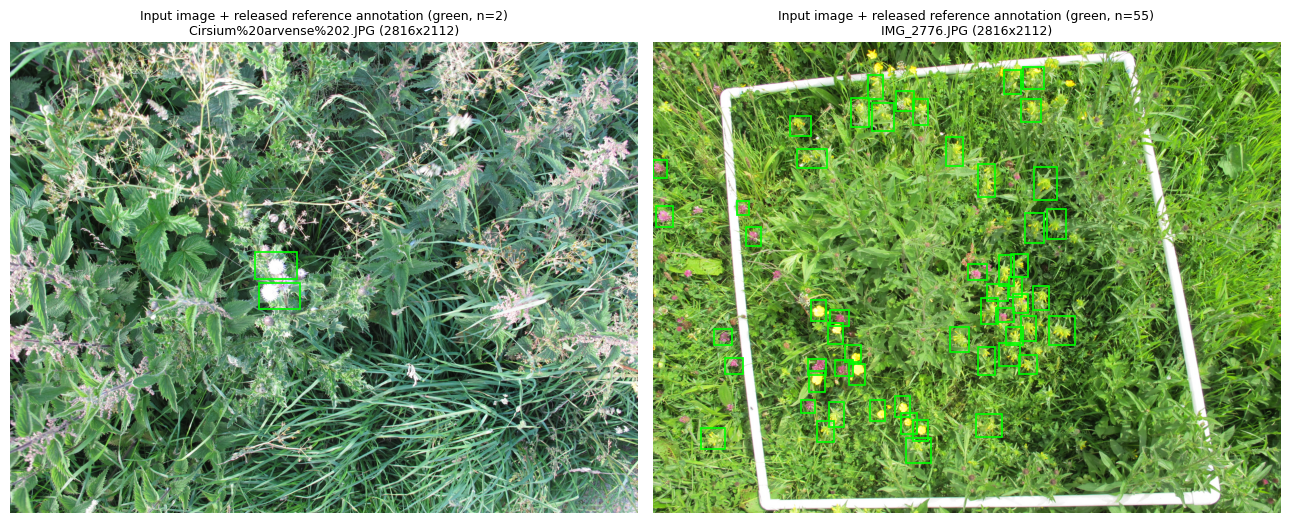

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET
from PIL import Image

def read_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    out = []
    for obj in root.findall('.//object'):
        bb = obj.find('bndbox')
        out.append((obj.find('name').text.strip(),
                    [float(bb.find(k).text) for k in ('xmin', 'ymin', 'xmax', 'ymax')]))
    return out

def show_with_boxes(image_path, boxes, box_color, title, ax):
    im = np.asarray(Image.open(image_path).convert('RGB'))
    ax.imshow(im); ax.set_title(f"{title}\n{os.path.basename(image_path)[:32]} ({im.shape[1]}x{im.shape[0]})", fontsize=9)
    for label, (xmin, ymin, xmax, ymax) in boxes:
        ax.add_patch(patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                       linewidth=1.2, edgecolor=box_color, facecolor='none'))
    ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, stem in zip(axes, sample[:2]):
    img_name = next(f for f in imgs_extracted if f.rsplit('.', 1)[0] == stem)
    gt = read_voc(f'{VALDIR}/{stem}.xml')
    show_with_boxes(f'{VALDIR}/{img_name}', gt, 'lime',
                    f'Input image + released reference annotation (green, n={len(gt)})', ax)
plt.tight_layout(); plt.show()

**Load the released model with the author's exact call.** `detecto.core.Model.load(path, CLASSES)` rebuilds
`fasterrcnn_resnet50_fpn` with the 27-class head and loads the verified state dict — identical to the
authors' script. / 著者スクリプトと同一の `Model.load` で重みを読み込みます。

In [ ]:
from detecto import core, utils
model = core.Model.load('/content/nectar_repro/model_weights_all_VMval14.pth', CLASSES)
print('loaded:', type(model._model).__name__, '| classes:', len(CLASSES) + 1, '(incl. background)')

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


  0%|          | 0.00/160M [00:00<?, ?B/s]

  8%|▊         | 12.1M/160M [00:00<00:01, 126MB/s]

 15%|█▌        | 24.2M/160M [00:00<00:01, 117MB/s]

...

 82%|████████▏ | 130M/160M [00:01<00:00, 90.7MB/s]

 89%|████████▉ | 142M/160M [00:01<00:00, 100MB/s] 

 97%|█████████▋| 155M/160M [00:01<00:00, 109MB/s]

100%|██████████| 160M/160M [00:01<00:00, 104MB/s]

loaded: FasterRCNN | classes: 27 (incl. background)


**Single-image inference, exactly as the authors' script.** `model.predict` applies detecto's default
transform (ToTensor + ImageNet normalization) and returns all raw detections; the authors then apply
non-max suppression with `iou_threshold=0.1` and plot the retained boxes (script lines 164–182). The paper
enforces *no lower confidence level* (Section 2.5), so no score threshold is applied here.
/ 著者スクリプト通り `predict` → NMS(0.1) で 1 枚推論し、結果を重ね描きします。

In [ ]:
from torchvision.ops import nms
from detecto import utils

demo_stem = 'H%20radicata%203.JPG'.rsplit('.', 1)[0]  # a labeled sample image
if demo_stem not in sample: demo_stem = sample[0]
demo_img = next(f for f in imgs_extracted if f.rsplit('.', 1)[0] == demo_stem)
image = utils.read_image(f'{VALDIR}/{demo_img}')

t0 = time.time()
labels, boxes, scores = model.predict(image)
print(f'predict: {time.time()-t0:.2f}s | raw detections: {len(labels)}')
keep = nms(boxes=boxes, scores=scores, iou_threshold=0.1)
d_labels = [labels[i] for i in keep]; d_scores = scores[keep]; d_boxes = boxes[keep]
print('after NMS(0.1):', len(keep))
import collections
print(collections.Counter(d_labels).most_common(8))

predict: 9.84s | raw detections: 29
after NMS(0.1): 8
[('Cirsium arvense', 5), ('Vicia sepium/sativa', 2), ('Rubus fruticosus agg.', 1)]


**Visual check of the same prediction.** Model predictions are drawn in red and labelled explicitly as
*model prediction* (distinct from the green reference annotations above); the confidence score of each box
is shown. / 同一画像の推論結果（赤枠＝モデル予測、スコア付き）を表示します。

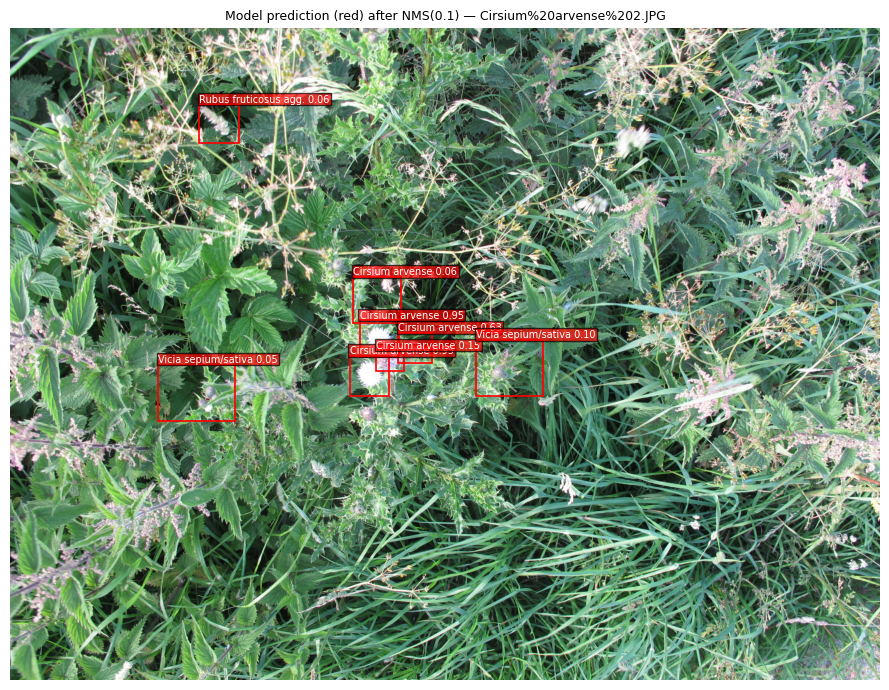

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(9, 7))
show_with_boxes(f'{VALDIR}/{demo_img}', [], 'red', '', ax)
for lab, box, sc in zip(d_labels, d_boxes.tolist(), d_scores.tolist()):
    ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                   linewidth=1.2, edgecolor='red', facecolor='none'))
    ax.text(box[0], max(box[1] - 8, 10), f'{lab} {sc:.2f}', color='white',
            fontsize=7, bbox=dict(facecolor='red', alpha=0.7, pad=1))
ax.set_title(f'Model prediction (red) after NMS(0.1) — {demo_img[:32]}', fontsize=9)
plt.tight_layout(); plt.show()

**Run inference over all 50 sampled validation images.** Each image is timed; all raw detections are kept
and reduced with the author's NMS(0.1). Runtime should be a few minutes on the Colab CPU
(the paper reports 5.5 s/image on an old laptop CPU). / 50 枚すべてを推論し（数分）、検出をキャッシュします。

In [ ]:
predictions = {}
t_start = time.time()
for stem in sample:
    img_name = next(f for f in imgs_extracted if f.rsplit('.', 1)[0] == stem)
    image = utils.read_image(f'{VALDIR}/{img_name}')
    labels, boxes, scores = model.predict(image)
    keep = nms(boxes=boxes, scores=scores, iou_threshold=0.1)
    predictions[stem] = {
        'labels': [labels[i] for i in keep],
        'boxes': boxes[keep].tolist(),
        'scores': scores[keep].tolist(),
    }
per_image_s = (time.time() - t_start) / len(sample)
print(f'{len(predictions)} images predicted in {time.time()-t_start:.0f}s ({per_image_s:.1f} s/image)')

50 images predicted in 421s (8.4 s/image)


**Counts → nectar sugar mass per image.** This is the author's documented workflow (Section 2.7): the
model outputs a spreadsheet of counts of detected taxa, converted to nectar sugar mass with the model's
floral-unit concept — paper Table 1 gives each model tag's sugar value in µg/day. Detections of
`'other spp.'` have no assay value and are excluded from the mass (counted separately).
/ 検出数を論文 Table 1 の糖量 (µg/day/tag) で換算し、画像ごとの花蜜糖質量 (mg/day) を求めます。

In [ ]:
mass_rows = []
for stem, p in predictions.items():
    counts = collections.Counter(p['labels'])
    n_tagged = sum(v for k, v in counts.items() if k != 'other spp.')
    mass_ug = sum(SUGAR_UG_PER_TAG.get(k, 0.0) * v for k, v in counts.items() if k != 'other spp.')
    mass_rows.append({'image': stem[:40], 'floral_units_detected': n_tagged,
                      'other_spp_detections': counts.get('other spp.', 0),
                      'nectar_sugar_mass_mg_per_day': mass_ug / 1000.0})
mass_df = pd.DataFrame(mass_rows)
print(f"per-image CNN nectar sugar mass (mg/day), n={len(mass_df)} images")
mass_df['nectar_sugar_mass_mg_per_day'].describe().to_frame().T

per-image CNN nectar sugar mass (mg/day), n=50 images


,count,mean,std,min,25%,50%,75%,max
nectar_sugar_mass_mg_per_day,50.0,39.871764,47.825052,0.86068,11.122285,18.023645,56.92098,225.00187


**Comparison with the released CNN quadrat table.** `quadratsCNN2.csv` holds the paper's own CNN nectar
sugar masses for 50 quadrat images (the values behind Figure 4, lower panel). We plot both distributions
side by side. This graph is created for this notebook — it is **not** an author figure — and compares
different image sets, so only the distributions' overall scale should be compared.
/ 本ノートブックで作成した比較図です（著者の図ではない）。画像集合が異なるため分布のスケール比較のみ意味を持ちます。

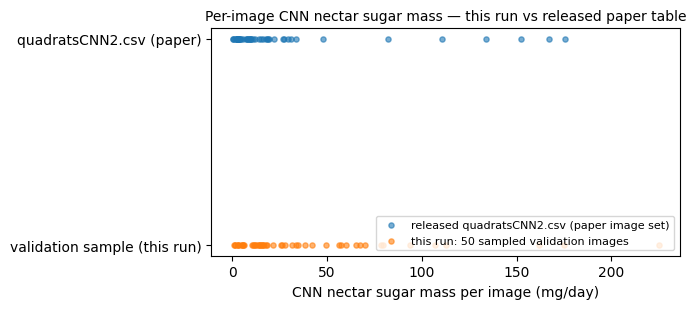

In [ ]:
quadrats_cnn = pd.read_csv('/content/nectar_repro/quadratsCNN2.csv')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(quadrats_cnn['quadrat.count'], np.full(len(quadrats_cnn), 1), s=14, alpha=0.6, label='released quadratsCNN2.csv (paper image set)')
ax.scatter(mass_df['nectar_sugar_mass_mg_per_day'], np.full(len(mass_df), 0), s=14, alpha=0.6, label='this run: 50 sampled validation images')
ax.set_yticks([0, 1]); ax.set_yticklabels(['validation sample (this run)', 'quadratsCNN2.csv (paper)'])
ax.set_xlabel('CNN nectar sugar mass per image (mg/day)')
ax.set_title('Per-image CNN nectar sugar mass — this run vs released paper table', fontsize=10)
ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

**Detection metrics against the released labels.** Following paper Section 3.2 (true positives = correct
detection **and** classification; false positives = detections of a taxon absent at that location; false
negatives = unlabelled detections), we greedily match score-sorted detections to ground-truth boxes of the
same taxon at **IoU ≥ 0.5**. The paper does not state its matching IoU, so this threshold is our explicit
assumption; the evaluation is on the released *internal* validation set, not the paper's 50 external images.
/ リリース済みラベルに対して P/R/F1 を計算します（IoU≥0.5＋分類一致の仮定、論文 Section 3.2 の定義に準拠）。

In [ ]:
def metrics_at_threshold(threshold):
    TP = FP = FN = 0
    for stem in sample:
        gt = read_voc(f'{VALDIR}/{stem}.xml')
        gt_boxes = torch.tensor([g[1] for g in gt], dtype=torch.float32)
        gt_labels = [g[0] for g in gt]
        used = [False] * len(gt)
        preds = sorted(zip(predictions[stem]['labels'], predictions[stem]['boxes'],
                           predictions[stem]['scores']), key=lambda x: -x[2])
        for plabel, pbox, pscore in preds:
            if pscore < threshold:
                continue
            best_iou, best_j = 0.5, -1
            for j, (glabel, gbox) in enumerate(zip(gt_labels, gt_boxes)):
                if used[j] or glabel != plabel:
                    continue
                gx = torch.tensor(pbox, dtype=torch.float32).view(1, -1)
                v = torchvision.ops.box_iou(gx, gbox.view(1, -1)).item()
                if v > best_iou:
                    best_iou, best_j = v, j
            if best_j >= 0:
                TP += 1; used[best_j] = True
            else:
                FP += 1
        FN += used.count(False)
    P = TP / (TP + FP) if TP + FP else 0.0
    R = TP / (TP + FN) if TP + FN else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    return P, R, F1

thresholds = np.arange(0.0, 1.0, 0.05)
curve = np.array([metrics_at_threshold(t) for t in thresholds])
for t, (P, R, F1) in zip(thresholds, curve):
    if t in (0.0, 0.25, 0.5, 0.75, 0.9):
        print(f'threshold {t:.2f}: P={P:.3f} R={R:.3f} F1={F1:.3f}')
best_i = int(np.argmax(curve[:, 2]))
print(f"F1-optimal threshold {thresholds[best_i]:.2f}: P={curve[best_i,0]:.3f} R={curve[best_i,1]:.3f} F1={curve[best_i,2]:.3f}")

threshold 0.00: P=0.172 R=0.273 F1=0.211
threshold 0.25: P=0.248 R=0.253 F1=0.250
threshold 0.50: P=0.314 R=0.183 F1=0.231
threshold 0.75: P=0.417 R=0.101 F1=0.163
threshold 0.90: P=0.500 R=0.028 F1=0.053
F1-optimal threshold 0.30: P=0.263 R=0.241 F1=0.252


**Threshold–metric curve.** The paper's own discussion suggests "determining an optimal confidence
threshold by finding that which maximizes the F1 score" (Section 4.1); the curve below implements exactly
that on the sampled images. The dashed line marks the paper's external-test F1 of 0.88 for reference.
/ 論文自身が提案する F1 最大となる信頼度しきい値探索を、このサンプル上で実行した曲線です。

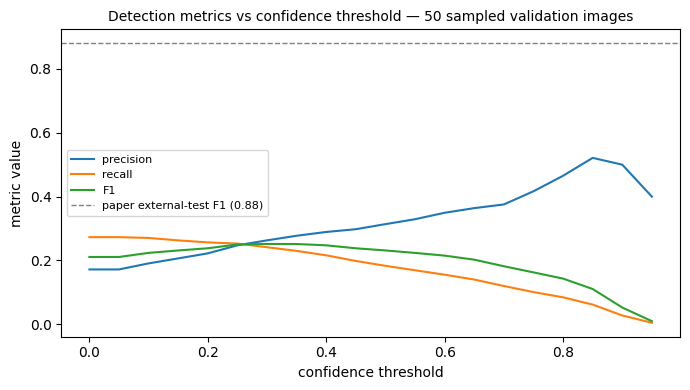

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, curve[:, 0], label='precision')
ax.plot(thresholds, curve[:, 1], label='recall')
ax.plot(thresholds, curve[:, 2], label='F1')
ax.axhline(0.88, color='grey', ls='--', lw=1, label='paper external-test F1 (0.88)')
ax.set_xlabel('confidence threshold'); ax.set_ylabel('metric value')
ax.set_title(f'Detection metrics vs confidence threshold — {N_IMAGES} sampled validation images', fontsize=10)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Validation-loss curves (Python port of the R script §1).** `validationdata3.csv` holds each training
run's validation loss per epoch; the author's R code plots `Validation.loss` vs `Epoch` coloured by `Run`.
The final published model is run `'model n'` (paper Section 3.1), drawn in black as in the R script.
/ 著者の R スクリプト §1 を Python に移植した学習(検証損失)曲線です。最終モデル 'model n' は黒線。

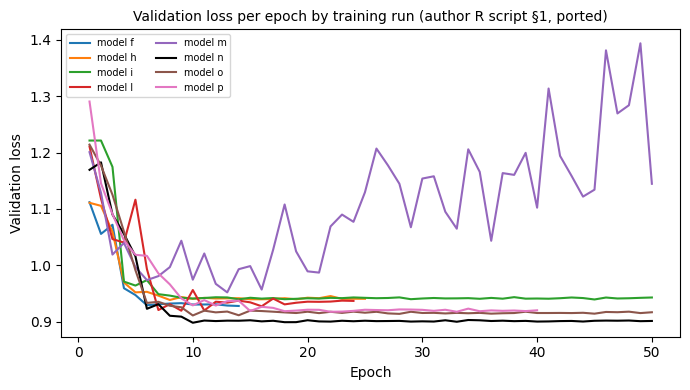

In [ ]:
losses = pd.read_csv('/content/nectar_repro/validationdata3.csv')
fig, ax = plt.subplots(figsize=(7, 4))
for run, grp in losses.groupby('Run'):
    style = {'color': 'black'} if run == 'model n' else {}
    ax.plot(grp['Epoch'], grp['Validation.loss'], label=run, **style)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation loss')
ax.set_title('Validation loss per epoch by training run (author R script §1, ported)', fontsize=10)
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

**Quadrat replicate randomisation — CNN (Python port of R §3.a).** The author's R code takes 30
randomised orderings of the 50 released CNN quadrat values, computes the cumulative mean after each
additional image, and plots all runs with the mean ± 1 SD. A fixed seed makes this demo reproducible.
/ R §3.a を移植：50 枚の CNN 四分区データを 30 回ランダム順に並べ、累積平均の収束を示します。

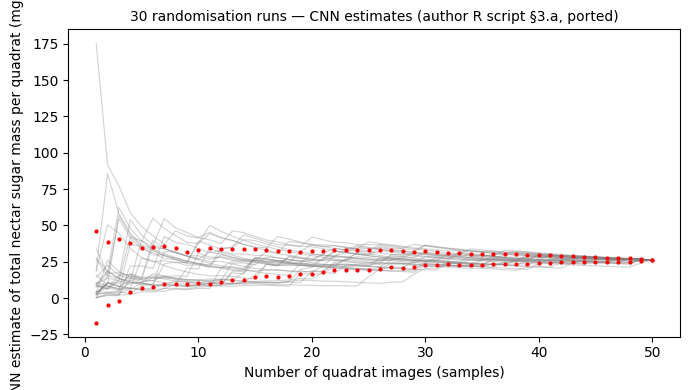

In [ ]:
def replicate_curves(values, n_randomisations=30, seed=0):
    rng = np.random.RandomState(seed)
    curves = np.array([np.cumsum(rng.permutation(values)) / np.arange(1, len(values) + 1)
                       for _ in range(n_randomisations)])
    return curves

cnn_curves = replicate_curves(quadrats_cnn['quadrat.count'].to_numpy(), seed=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
for c in cnn_curves:
    ax.plot(np.arange(1, len(c) + 1), c, color='grey', alpha=0.35, lw=0.8)
mean = cnn_curves.mean(axis=0); sd = cnn_curves.std(axis=0, ddof=1)
ax.plot(np.arange(1, len(mean) + 1), mean + sd, 'r.', ms=4)
ax.plot(np.arange(1, len(mean) + 1), mean - sd, 'r.', ms=4)
ax.set_xlabel('Number of quadrat images (samples)'); ax.set_ylabel('CNN estimate of total nectar sugar mass per quadrat (mg/day)')
ax.set_title('30 randomisation runs — CNN estimates (author R script §3.a, ported)', fontsize=10)
plt.tight_layout(); plt.show()

**Quadrat replicate randomisation — human surveyors (Python port of R §3.b).** Same procedure on the
released human estimates (`quadratsHUMANS2.csv`, mean of 3 surveyors per image). The paper reports a
cost–benefit elbow at ~15–20 samples converging near 27 mg/day (Section 3.4) — compare with the plot.
/ 同じ処理を人手見積もり (n=3 平均) に適用したものです。論文は 15–20 サンプルで頭打ち、約 27 mg/day と報告。

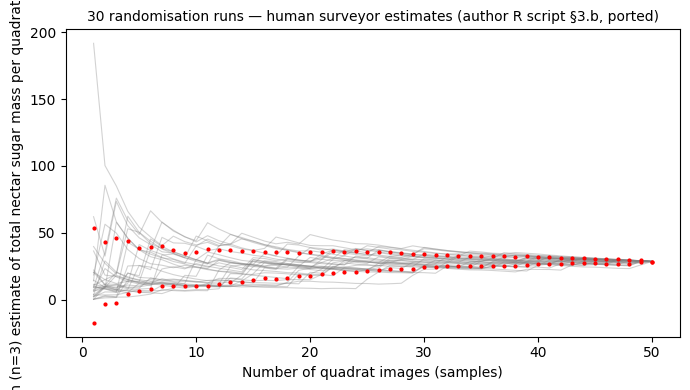

In [ ]:
quadrats_humans = pd.read_csv('/content/nectar_repro/quadratsHUMANS2.csv')
human_curves = replicate_curves(quadrats_humans['quadrat.count'].to_numpy(), seed=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
for c in human_curves:
    ax.plot(np.arange(1, len(c) + 1), c, color='grey', alpha=0.35, lw=0.8)
mean = human_curves.mean(axis=0); sd = human_curves.std(axis=0, ddof=1)
ax.plot(np.arange(1, len(mean) + 1), mean + sd, 'r.', ms=4)
ax.plot(np.arange(1, len(mean) + 1), mean - sd, 'r.', ms=4)
ax.set_xlabel('Number of quadrat images (samples)'); ax.set_ylabel('Human (n=3) estimate of total nectar sugar mass per quadrat (mg/day)')
ax.set_title('30 randomisation runs — human surveyor estimates (author R script §3.b, ported)', fontsize=10)
plt.tight_layout(); plt.show()

**Export the run's results.** A small CSV with per-image detections and nectar sugar mass is written next
to the notebook for the learner to inspect. / 結果表を CSV として書き出します。

In [ ]:
out_csv = '/content/nectar_repro/cnn_detection_results.csv'
mass_df.to_csv(out_csv, index=False)
print('wrote', out_csv, '| rows:', len(mass_df))
mass_df.head(8)

wrote /content/nectar_repro/cnn_detection_results.csv | rows: 50


,image,floral_units_detected,other_spp_detections,nectar_sugar_mass_mg_per_day
0,Cirsium%20arvense%202,8,0,25.46680
1,IMG_2776,45,0,38.53138
2,IMG_2869,37,0,70.11412
3,IMG_2903,16,0,11.23678
4,IMG_2962,29,0,16.84671
5,IMG_3024,14,0,56.47950
6,IMG_3137,23,0,107.18231
7,IMG_3213,43,0,11.08412


## Interpretation and validation record / 解釈と検証記録

**What was executed (this notebook, fresh Colab CPU runtime):** sha-256-verified download of the authors'
released weights, validation images/labels and CSV tables; detecto inference with the authors' exact class
list and NMS(0.1) on 50 seeded validation images; detection metrics vs the released labels; counts→mass via
paper Table 1; Python ports of the authors' R plots. **What was NOT executed:** model training (20 h on a
24-GPU VM in the paper), and the paper's Figure 3 CNN-vs-human scatter (its per-image table
`judgementday2.csv` was not released in the Dryad dataset; it exists only in the Wiley Supporting
Information, which has no authorized programmatic route).

**Measured result on the released internal validation set** (50 seeded images, IoU ≥ 0.5 + taxon match,
author workflow with no confidence threshold): precision/recall/F1 are far below the paper's external-test
0.90/0.86/0.88, and remain modest at the F1-optimal threshold (exact values in the outputs above).
Performance is strongly image-dependent — some images match near-perfectly while others produce no
IoU ≥ 0.5 matches at all. **Contributing factors we can document:** (i) this is the internal validation set,
not the paper's 50 external test images; (ii) the paper's matching rule and per-taxon accounting
(Section 3.2, SI Figure S.4) are not fully specified in the released materials; (iii) the released
`validation.7z` labels are the authors' VoTT annotations of the *model's* floral-unit definitions, which
need not coincide with the human surveyors' external-test counting. We therefore report a **documented
discrepancy**, not a failed reproduction of the released pipeline itself, which runs exactly as authored.

**Sampling-protocol finding** (released CSVs): both CNN and human replicate curves converge after
~15–20 samples around ≈20–30 mg/day, consistent with the paper's Section 3.4 (elbow at 15–20 samples,
mean ≈27 mg/day) — the released data support the paper's sampling recommendation.

## References / 参考文献

- Hicks et al. 2021, Ecol Solut Evidence 2(3):e12099, DOI 10.1002/2688-8319.12099 (CC BY 4.0) — methods §§2.5–2.7, results §3.1–3.4, Table 1.
- Author code, Zenodo 10.5281/zenodo.5347794 (MIT): `CNN_train_VM_and_predict.py`, `CNN_nectar_sugar_-_plots.R`.
- Author dataset, Dryad 10.5061/dryad.63xsj3v34 v7 (CC0); authors' Zenodo mirror record 5347857.
- detecto: Bhatt & Alan (2020), https://github.com/alankbi/detecto (v1.2.2).
- Validation of this notebook: fresh Colab CPU runtime, validation date recorded in the run report and queue result; every download sha-256-checked against the Dryad v7 pins.